### Clasificación de artículos de noticias de la BBC con Transformers (BERT)

Objetivo: asignar a cada artículo de la BBC su categoría temática (business, entertainment, politics, sport o tech).

Aunque el enunciado habla de "multi-etiqueta", cada artículo del dataset tiene una sola categoría. Por eso se resuelve como un problema multi-clase con salida softmax, como pide la actividad 3.

Pipeline:
1. Limpieza del texto y tokenización con el tokenizer WordPiece de BERT.
2. Paso a secuencias de ids con máscara de atención (máximo 512 tokens).
3. Fine-tuning de `BertForSequenceClassification` (`bert-base-uncased`) con una capa de salida de 5 clases y softmax.

El modelo se entrena con 3 semillas. En prueba se reportan exactitud, precisión, recall y F1 (macro) como media ± desviación estándar, además de un análisis por categoría.

### 1. Configuración y datos

In [1]:
#!pip -q install transformers kagglehub

In [ ]:
import os, re, glob, random, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import BertTokenizerFast, BertForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix, classification_report)

hf_logging.set_verbosity_error()   

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')   
else:
    device = torch.device('cpu')
print('Dispositivo:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

FIG_DIR = './resultados'
os.makedirs(FIG_DIR, exist_ok=True)

MODELO = 'bert-base-uncased'
MAX_LEN = 512      # máximo de tokens que admite BERT
BATCH = 16         # si la GPU se queda sin memoria, bajar a 8
EPOCAS = 3         # el enunciado sugiere 2 a 5
LR = 2e-5
USAR_AMP = device.type == 'cuda'


def fijar_semilla(s):
    """Hace reproducibles los experimentos."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Dispositivo: cuda
GPU: Tesla T4


In [3]:
import kagglehub

DATA_DIR = kagglehub.dataset_download('jacopoferretti/bbc-articles-dataset')
csvs = glob.glob(os.path.join(DATA_DIR, '**', '*.csv'), recursive=True)
print('Archivos CSV:', csvs)

# Se usa el primer CSV que tenga una columna de texto y una de categoría
df = None
for ruta in csvs:
    tmp = pd.read_csv(ruta)
    col_etiqueta = next((c for c in ['labels', 'label', 'category'] if c in tmp.columns), None)
    if 'text' in tmp.columns and col_etiqueta:
        df = tmp
        print('Usando:', ruta, '| columnas:', list(tmp.columns))
        break
assert df is not None, 'Ningún CSV tiene las columnas text + labels/label/category'

df = df[['text', col_etiqueta]].dropna().rename(columns={col_etiqueta: 'categoria'})
df['categoria'] = df['categoria'].astype(str).str.strip().str.lower()
print('Artículos:', len(df))
df.head()

Using Colab cache for faster access to the 'bbc-articles-dataset' dataset.
Archivos CSV: ['/kaggle/input/bbc-articles-dataset/bbc_news_text_complexity_summarization.csv', '/kaggle/input/bbc-articles-dataset/archive (2)/bbc-news-data.csv', '/kaggle/input/bbc-articles-dataset/archive/bbc_text_cls.csv']
Usando: /kaggle/input/bbc-articles-dataset/bbc_news_text_complexity_summarization.csv | columnas: ['text', 'labels', 'no_sentences', 'Flesch Reading Ease Score', 'Dale-Chall Readability Score', 'text_rank_summary', 'lsa_summary']
Artículos: 2127


,text,categoria
0,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,High fuel prices hit BA's profits\n\nBritish A...,business
4,Pernod takeover talk lifts Domecq\n\nShares in...,business


### 2. Exploración
Se revisa el balance de clases y el largo de los artículos en tokens de BERT. Con el largo se comprueba cuántos artículos caben completos en `MAX_LEN = 512`, el resto se trunca.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

count    2127.0
mean      487.0
std       297.0
min       108.0
50%       421.0
75%       592.0
90%       775.0
max      5303.0
Name: n_tokens, dtype: float64
Artículos con <= 512 tokens: 64.3%


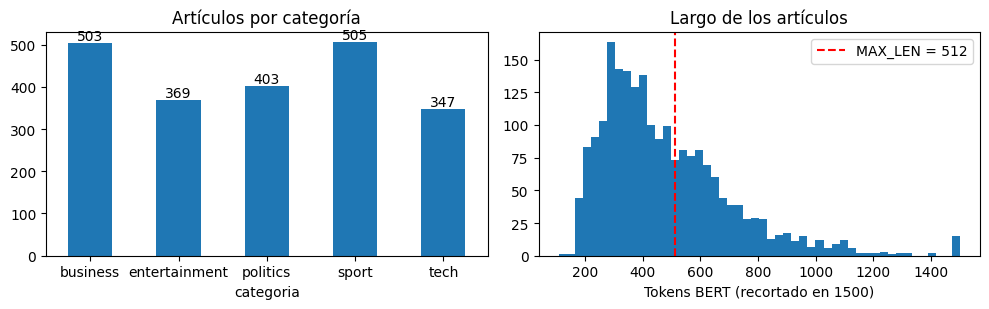

In [4]:
tokenizer = BertTokenizerFast.from_pretrained(MODELO)

df['n_tokens'] = [len(ids) for ids in tokenizer(df['text'].tolist())['input_ids']]
print(df['n_tokens'].describe(percentiles=[0.5, 0.75, 0.9]).round(0))
print(f'Artículos con <= {MAX_LEN} tokens: {(df["n_tokens"] <= MAX_LEN).mean():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
conteo = df['categoria'].value_counts().sort_index()
conteo.plot.bar(ax=axes[0], rot=0, title='Artículos por categoría')
axes[0].bar_label(axes[0].containers[0])
axes[1].hist(df['n_tokens'].clip(upper=1500), bins=50)
axes[1].axvline(MAX_LEN, color='red', ls='--', label=f'MAX_LEN = {MAX_LEN}')
axes[1].set(title='Largo de los artículos', xlabel='Tokens BERT (recortado en 1500)')
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/exploracion.png', dpi=300)
plt.show()

### 3. Limpieza y división
- Limpieza: solo se unifican espacios y saltos de línea. No se quitan stopwords ni signos de puntuación porque BERT usa el contexto completo de la frase. Tampoco hace falta pasar a minúsculas a mano, porque el tokenizer *uncased* ya lo hace.
- Duplicados: el dataset de la BBC trae artículos repetidos. Si una copia queda en train y otra en test, las métricas salen infladas. Por eso se deja una copia por texto y se eliminan los textos que aparecen con categorías distintas.
- Etiquetas: cada categoría se convierte en un entero de 0 a 4 (`label2id`), que es el formato que espera `BertForSequenceClassification` para la entropía cruzada multi-clase.
- División: estratificada, 70 % train / 15 % validación / 15 % prueba.

In [5]:
def limpiar(texto):
    """Unifica espacios y saltos de línea."""
    return re.sub(r'\s+', ' ', str(texto)).strip()


print(repr(limpiar('Ad sales boost Time Warner profit\n\n Quarterly profits at US media giant...')))

df['limpio'] = df['text'].map(limpiar)
df = df[df['limpio'].str.len() > 0]

conflicto = df.groupby('limpio')['categoria'].transform('nunique') > 1   # mismo texto, distinta categoría
df_limpio = df[~conflicto].drop_duplicates('limpio').reset_index(drop=True)
print(f'Originales: {len(df)} | en conflicto: {conflicto.sum()} | finales: {len(df_limpio)}')

CLASES = sorted(df_limpio['categoria'].unique())
label2id = {c: i for i, c in enumerate(CLASES)}
df_limpio['label'] = df_limpio['categoria'].map(label2id)
print('Clases:', label2id)

df_train, df_temp = train_test_split(df_limpio, test_size=0.3, stratify=df_limpio['label'], random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=0.5, stratify=df_temp['label'], random_state=42)

pd.DataFrame({'train': df_train['label'].value_counts(),
              'val': df_val['label'].value_counts(),
              'test': df_test['label'].value_counts()}).sort_index().rename(index=dict(enumerate(CLASES)))

'Ad sales boost Time Warner profit Quarterly profits at US media giant...'
Originales: 2127 | en conflicto: 0 | finales: 2125
Clases: {'business': 0, 'entertainment': 1, 'politics': 2, 'sport': 3, 'tech': 4}


,train,val,test
label,,,
business,352,75,76
entertainment,258,56,55
politics,282,60,61
sport,352,76,75
tech,243,52,52


### 4. Tokenización con BERT
- El tokenizer WordPiece de `bert-base-uncased` divide las palabras poco frecuentes en subpalabras (`##...`), así que no hay palabras desconocidas. Además agrega `[CLS]` al inicio y `[SEP]` al final.
- Cada artículo se trunca a `MAX_LEN` tokens y se rellena con `[PAD]` (id 0) hasta ese largo.
- La `attention_mask` vale 1 en los tokens reales y 0 en el relleno, para que la atención ignore el padding.
- Los embeddings de cada token salen de la capa de embeddings preentrenada de BERT (token + posición + segmento) y se ajustan durante el fine-tuning.

In [6]:
def a_dataset(tabla):
    """Devuelve un TensorDataset con (input_ids, attention_mask, etiquetas)."""
    enc = tokenizer(tabla['limpio'].tolist(), truncation=True, padding='max_length',
                    max_length=MAX_LEN, return_tensors='pt')
    y = torch.tensor(tabla['label'].values, dtype=torch.long)
    return TensorDataset(enc['input_ids'], enc['attention_mask'], y)


ds_train, ds_val, ds_test = a_dataset(df_train), a_dataset(df_val), a_dataset(df_test)
loader_val = DataLoader(ds_val, batch_size=64)
loader_test = DataLoader(ds_test, batch_size=64)

ids0, mask0, y0 = ds_train[0]
print('Artículo:', df_train['limpio'].iloc[0][:150], '...')
print('Tokens:', tokenizer.convert_ids_to_tokens(ids0[:20].tolist()))
print('Ids:', ids0[:20].tolist())
print('Tokens reales:', mask0.sum().item(), '| etiqueta:', CLASES[y0])

Artículo: Brown and Blair face new rift claims For the umpteenth time, Tony Blair and Gordon Brown are said to have declared all out war on each other. This tim ...
Tokens: ['[CLS]', 'brown', 'and', 'blair', 'face', 'new', 'rift', 'claims', 'for', 'the', 'um', '##pt', '##een', '##th', 'time', ',', 'tony', 'blair', 'and', 'gordon']
Ids: [101, 2829, 1998, 10503, 2227, 2047, 16931, 4447, 2005, 1996, 8529, 13876, 12129, 2705, 2051, 1010, 4116, 10503, 1998, 5146]
Tokens reales: 512 | etiqueta: politics


### 5. Modelo
Se usa `BertForSequenceClassification` con `bert-base-uncased`:

- Por qué BERT-base uncased: está preentrenado con textos en inglés (Wikipedia + BookCorpus), igual que las noticias de la BBC, y su atención bidireccional lee todo el artículo a la vez sin procesarlo de forma secuencial como una RNN. La versión base (12 capas, 768 dimensiones, unos 110 M parámetros) cabe en una GPU T4 con 512 tokens. En noticias las mayúsculas aportan poco a la categoría, por eso se usa uncased.
- Codificador BERT (12 capas transformer): genera una representación contextual de cada token. El vector del token `[CLS]` pasa por la capa *pooler* (densa 768 → 768 + tanh) y queda como resumen de todo el artículo.
- Dropout (0.1): regulariza la representación antes de clasificar.
- Capa de salida nueva, densa 768 → 5: es la única capa que se agrega. Convierte el resumen en un logit por categoría.
- Softmax: convierte los 5 logits en probabilidades que suman 1, así que cada artículo recibe exactamente una categoría. En entrenamiento la softmax va dentro de `CrossEntropyLoss` (log-softmax + NLL) por estabilidad numérica, y al predecir se aplica de forma explícita.

Se hace fine-tuning completo: se ajustan tanto los pesos de BERT como los de la capa nueva, para adaptar las representaciones al vocabulario periodístico.

In [7]:
def crear_modelo():
    return BertForSequenceClassification.from_pretrained(
        MODELO, num_labels=len(CLASES),
        id2label=dict(enumerate(CLASES)), label2id=label2id).to(device)


modelo = crear_modelo()
print(modelo.classifier)
print(f'Parámetros: {sum(p.numel() for p in modelo.parameters()):,}')
del modelo

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Linear(in_features=768, out_features=5, bias=True)
Parámetros: 109,486,085


### 6. Entrenamiento
- Optimizador AdamW (lr 2e-5, weight decay 0.01), que es la configuración estándar de fine-tuning de BERT.
- Tasa de aprendizaje con un warmup lineal del 10 % de los pasos y luego un decaimiento lineal a 0, para no dañar los pesos preentrenados en los primeros pasos.
- Batch de 16, `EPOCAS = 3` y pérdida de entropía cruzada multi-clase.
- Gradient clipping a norma 1.0 y precisión mixta (fp16) en GPU.
- Al final se conservan los pesos de la época con menor pérdida de validación.

In [8]:
criterio = nn.CrossEntropyLoss()   # aplica log-softmax internamente


def correr_epoca(modelo, loader, optimizador=None, scheduler=None, scaler=None):
    """Una pasada por el loader: entrena si recibe optimizador, si no solo evalúa. Devuelve (pérdida, exactitud)."""
    entrenar = optimizador is not None
    modelo.train(entrenar)
    perdida, aciertos = 0.0, 0
    with torch.set_grad_enabled(entrenar):
        for ids, mask, y in loader:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP):
                logits = modelo(input_ids=ids, attention_mask=mask).logits
                loss = criterio(logits, y)
            if entrenar:
                optimizador.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizador)
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                scaler.step(optimizador)
                scaler.update()
                scheduler.step()
            perdida += loss.item() * len(y)
            aciertos += (logits.argmax(1) == y).sum().item()
    n = len(loader.dataset)
    return perdida / n, aciertos / n


def entrenar(modelo, loader_train, epocas=EPOCAS, lr=LR):
    """Entrena y deja en el modelo los pesos de la mejor época de validación."""
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    pasos = epocas * len(loader_train)
    scheduler = get_linear_schedule_with_warmup(optimizador, int(0.1 * pasos), pasos)
    scaler = torch.amp.GradScaler('cuda', enabled=USAR_AMP)
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    mejor, mejores_pesos = float('inf'), None
    for ep in range(1, epocas + 1):
        tl, ta = correr_epoca(modelo, loader_train, optimizador, scheduler, scaler)
        vl, va = correr_epoca(modelo, loader_val)
        for k, v in zip(hist, [tl, ta, vl, va]):
            hist[k].append(v)
        print(f'  época {ep:2d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')
        if vl < mejor:
            mejor = vl
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(mejores_pesos)
    return hist


@torch.no_grad()
def predecir(modelo, loader):
    """Devuelve (y_true, y_pred, probabilidades softmax por clase)."""
    modelo.eval()
    probs = []
    for ids, mask, _ in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USAR_AMP):
            logits = modelo(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        probs.append(torch.softmax(logits.float(), dim=1).cpu())
    probs = torch.cat(probs).numpy()
    y_true = loader.dataset.tensors[2].numpy()
    return y_true, probs.argmax(1), probs

In [9]:
SEMILLAS = [0, 1, 2]

corridas = []   # una por semilla
for s in SEMILLAS:
    print(f'=== {MODELO} | semilla {s} ===')
    fijar_semilla(s)   # fija también la inicialización de la capa de salida
    loader_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True)
    modelo = crear_modelo()
    hist = entrenar(modelo, loader_train)

    y_true, y_pred, probs = predecir(modelo, loader_test)
    metricas = {'acc': accuracy_score(y_true, y_pred),
                'precision': precision_score(y_true, y_pred, average='macro'),
                'recall': recall_score(y_true, y_pred, average='macro'),
                'f1': f1_score(y_true, y_pred, average='macro')}
    print('  -> test ' + ' | '.join(f'{k} {v:.4f}' for k, v in metricas.items()) + '\n')

    corridas.append({'semilla': s, 'hist': hist, **metricas,
                     'y_true': y_true, 'y_pred': y_pred, 'probs': probs})
    if s == 0:
        modelo_final = modelo   # se guarda para el análisis cualitativo
    else:
        del modelo
        if device.type == 'cuda':
            torch.cuda.empty_cache()

=== bert-base-uncased | semilla 0 ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  época  1 | train loss 0.8651 acc 0.7512 | val loss 0.1806 acc 0.9718
  época  2 | train loss 0.0863 acc 0.9859 | val loss 0.1286 acc 0.9687
  época  3 | train loss 0.0250 acc 0.9960 | val loss 0.1105 acc 0.9749
  -> test acc 0.9906 | precision 0.9901 | recall 0.9909 | f1 0.9904

=== bert-base-uncased | semilla 1 ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  época  1 | train loss 0.8780 acc 0.7391 | val loss 0.1898 acc 0.9718
  época  2 | train loss 0.0778 acc 0.9879 | val loss 0.1170 acc 0.9655
  época  3 | train loss 0.0291 acc 0.9953 | val loss 0.1215 acc 0.9687
  -> test acc 0.9906 | precision 0.9901 | recall 0.9909 | f1 0.9904

=== bert-base-uncased | semilla 2 ===


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  época  1 | train loss 0.9043 acc 0.7323 | val loss 0.1894 acc 0.9655
  época  2 | train loss 0.0856 acc 0.9859 | val loss 0.1018 acc 0.9687
  época  3 | train loss 0.0295 acc 0.9946 | val loss 0.1092 acc 0.9687
  -> test acc 0.9875 | precision 0.9865 | recall 0.9876 | f1 0.9869



### 7. Resultados cuantitativos
Métricas en prueba (%), como media ± desviación estándar de las 3 semillas. Precisión, recall y F1 son *macro*, es decir, el promedio simple de las 5 categorías.

In [10]:
res = pd.DataFrame(corridas)
tabla = res[['acc', 'precision', 'recall', 'f1']].agg(['mean', 'std']).T.mul(100).round(2)
tabla.to_csv(f'{FIG_DIR}/tabla_resultados.csv')
tabla

,mean,std
acc,98.96,0.18
precision,98.89,0.20
recall,98.98,0.19
f1,98.92,0.20


In [11]:
# Precisión, recall y F1 por categoría (semilla 0)
print(classification_report(corridas[0]['y_true'], corridas[0]['y_pred'], target_names=CLASES, digits=4))

               precision    recall  f1-score   support

     business     1.0000    0.9737    0.9867        76
entertainment     0.9821    1.0000    0.9910        55
     politics     0.9683    1.0000    0.9839        61
        sport     1.0000    1.0000    1.0000        75
         tech     1.0000    0.9808    0.9903        52

     accuracy                         0.9906       319
    macro avg     0.9901    0.9909    0.9904       319
 weighted avg     0.9909    0.9906    0.9906       319



#### 7.1 Análisis por categoría
Precisión, recall y F1 de cada categoría (media ± desviación estándar de las 3 semillas). Sirve para ver en qué categorías el modelo rinde mejor y en cuáles peor.

Mejor precisión: business (100.00 %)
Peor precisión:  politics (96.81 %)


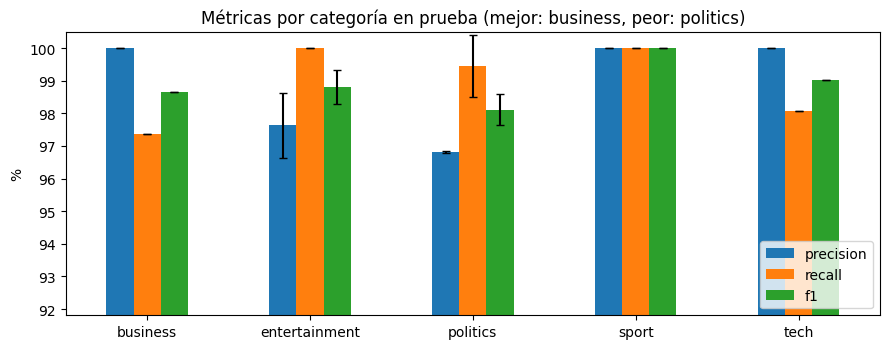

,precision,recall,f1
categoria,,,
business,100.0 ± 0.0,97.37 ± 0.0,98.67 ± 0.0
entertainment,97.64 ± 0.99,100.0 ± 0.0,98.8 ± 0.51
politics,96.81 ± 0.03,99.45 ± 0.95,98.11 ± 0.48
sport,100.0 ± 0.0,100.0 ± 0.0,100.0 ± 0.0
tech,100.0 ± 0.0,98.08 ± 0.0,99.03 ± 0.0


In [12]:
filas = []
for c in corridas:
    p, r, f, _ = precision_recall_fscore_support(c['y_true'], c['y_pred'], labels=range(len(CLASES)), zero_division=0)
    filas.append(pd.DataFrame({'categoria': CLASES, 'precision': p, 'recall': r, 'f1': f}))
por_clase = pd.concat(filas).groupby('categoria')[['precision', 'recall', 'f1']]
medias, desv = por_clase.mean().mul(100), por_clase.std().mul(100)

resumen = medias.round(2).astype(str) + ' ± ' + desv.round(2).astype(str)
resumen.to_csv(f'{FIG_DIR}/metricas_por_clase.csv')
mejor, peor = medias['precision'].idxmax(), medias['precision'].idxmin()
print(f'Mejor precisión: {mejor} ({medias.loc[mejor, "precision"]:.2f} %)')
print(f'Peor precisión:  {peor} ({medias.loc[peor, "precision"]:.2f} %)')

ax = medias.plot.bar(yerr=desv, rot=0, figsize=(9, 3.6), capsize=3)
ax.set(ylim=(max(0, medias.values.min() - 5), 100.5), ylabel='%', xlabel='',
       title=f'Métricas por categoría en prueba (mejor: {mejor}, peor: {peor})')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/metricas_por_clase.png', dpi=300)
plt.show()
resumen

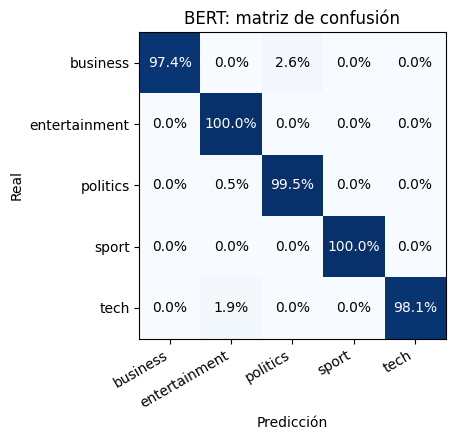

In [13]:
# Matriz de confusión: suma de las 3 semillas, normalizada por fila (%)
n = len(CLASES)
cm = sum(confusion_matrix(c['y_true'], c['y_pred'], labels=range(n)) for c in corridas)
cm = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Blues', vmin=0, vmax=100)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f'{cm[i, j]:.1f}%', ha='center', va='center', color='white' if cm[i, j] > 50 else 'black')
ax.set(xticks=range(n), yticks=range(n), xticklabels=CLASES, yticklabels=CLASES,
       title='BERT: matriz de confusión', xlabel='Predicción', ylabel='Real')
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/matriz_confusion.png', dpi=300)
plt.show()

### 8. Resultados cualitativos
#### 8.1 Curvas de aprendizaje (semilla 0)

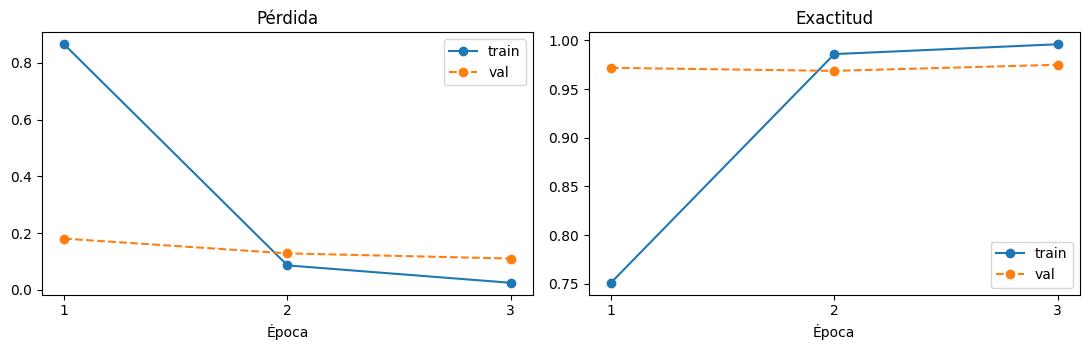

In [14]:
h = corridas[0]['hist']
epocas = range(1, len(h['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, m, titulo in zip(axes, ['loss', 'acc'], ['Pérdida', 'Exactitud']):
    ax.plot(epocas, h[f'train_{m}'], '-o', label='train')
    ax.plot(epocas, h[f'val_{m}'], '--o', label='val')
    ax.set(title=titulo, xlabel='Época', xticks=list(epocas))
    ax.legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/curvas_aprendizaje.png', dpi=300)
plt.show()

#### 8.2 Errores más confiados (semilla 0)
Artículos de prueba mal clasificados en los que el modelo estaba más seguro. R = real, P = predicción.

In [15]:
c = corridas[0]
confianza = c['probs'].max(axis=1)


def mostrar(i):
    """Imprime la clase real, la predicción y el inicio del texto de un artículo de prueba."""
    print(f'R: {CLASES[c["y_true"][i]]} | P: {CLASES[c["y_pred"][i]]} (p = {confianza[i]:.2f})')
    print('  ', df_test['limpio'].iloc[i][:400], '...\n')


errores = np.where(c['y_true'] != c['y_pred'])[0]
print(f'Errores en prueba: {len(errores)} de {len(c["y_true"])}\n')
for i in errores[np.argsort(-confianza[errores])][:5]:
    mostrar(i)

Errores en prueba: 3 de 319

R: business | P: politics (p = 0.99)
   Golden rule 'intact' says ex-aide Chancellor Gordon Brown will meet his golden economic rule "with a margin to spare", according to his former chief economic adviser. Formerly one of Mr Brown's closest Treasury aides, Ed Balls hinted at a Budget giveaway on 16 March. He said he hoped more would be done to build on current tax credit rules. Any rate rise ahead of an expected May election would not  ...

R: business | P: politics (p = 0.81)
   US bank boss hails 'genius' Smith US Federal Reserve chairman Alan Greenspan has given a speech at a Scottish church in honour of the pioneering economist, Adam Smith. He delivered the 14th Adam Smith Lecture in Kirkcaldy, Fife. The Adam Smith Lecture celebrates the author of 1776's Wealth of Nations, which became a bible of capitalism. Dr Greenspan was invited by Chancellor Gordon Brown, whose mi ...

R: tech | P: entertainment (p = 0.59)
   Web radio takes Spanish rap global Spi

#### 8.3 Predicción de textos nuevos
Titulares escritos a mano (uno por categoría), para ver la distribución softmax que da el modelo.

In [16]:
@torch.no_grad()
def predecir_texto(modelo, texto):
    """Texto crudo -> probabilidades softmax por categoría."""
    enc = tokenizer(limpiar(texto), truncation=True, max_length=MAX_LEN, return_tensors='pt').to(device)
    modelo.eval()
    return torch.softmax(modelo(**enc).logits.float(), dim=1)[0].cpu().numpy()


frases = ['The central bank raised interest rates again to fight rising inflation.',
          'The film won best picture at the Oscars and its lead actress was praised.',
          'The prime minister faces a vote in parliament over the new tax bill.',
          'The striker scored twice as his team won the cup final.',
          'The new smartphone has a faster chip and a longer battery life.']
tabla_frases = pd.DataFrame([predecir_texto(modelo_final, f) for f in frases], columns=CLASES).round(3)
tabla_frases.insert(0, 'frase', frases)
tabla_frases['prediccion'] = tabla_frases[CLASES].idxmax(axis=1)
tabla_frases

,frase,business,entertainment,politics,sport,tech,prediccion
0,The central bank raised interest rates again t...,0.972,0.004,0.007,0.008,0.009,business
1,The film won best picture at the Oscars and it...,0.038,0.826,0.042,0.038,0.055,entertainment
2,The prime minister faces a vote in parliament ...,0.013,0.004,0.972,0.005,0.005,politics
3,The striker scored twice as his team won the c...,0.010,0.004,0.006,0.974,0.006,sport
4,The new smartphone has a faster chip and a lon...,0.047,0.008,0.013,0.010,0.922,tech


### 9. Exportar resultados
Se comprimen las figuras y las tablas en `resultados_informe.zip` para descargarlas desde Colab.

In [17]:
shutil.make_archive('resultados_informe', 'zip', FIG_DIR)
try:
    from google.colab import files
    files.download('resultados_informe.zip')
except ImportError:
    print('Archivo listo:', os.path.abspath('resultados_informe.zip'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>